In [34]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.proportion import proportion_confint
from scipy.stats import chi2_contingency
sns.set_style('whitegrid')
%matplotlib inline

import sys
sys.path.append('../')

In [4]:
raw = pd.read_csv('../data/nuvem_fraud_dataset.csv', delimiter=';')
raw.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,"107,23",Mobile,Master Card,Orient,WA,48|8878,-118|2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49|159047,-118|186462,0
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,"220,11",Mobile,Amex,Malad City,ID,42|1808,-112|262,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43|150704,-112|154481,0
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,"96,29",Mobile,Amex,Grenada,CA,41|6125,-122|5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41|65752,-122|230347,0
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,"7,77",Mobile,Visa,High Rolls Mountain Park,NM,32|9396,-105|8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32|863258,-106|520205,0
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,"6,85",Web,Master Card,Freedom,WY,43|0172,-111|0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43|753735,-111|454923,0


In [5]:
raw= raw.reset_index(drop=True)
raw["row_orig"] = raw.index
raw = raw.sort_values(["created_at", "row_orig"]).reset_index(drop=True)
raw["txn_id"] = raw.index

In [9]:
raw.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud,row_orig,txn_id
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,"107,23",Mobile,Master Card,Orient,WA,48|8878,-118|2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49|159047,-118|186462,0,0,0
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,"220,11",Mobile,Amex,Malad City,ID,42|1808,-112|262,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43|150704,-112|154481,0,1,1
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,"96,29",Mobile,Amex,Grenada,CA,41|6125,-122|5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41|65752,-122|230347,0,2,2
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,"7,77",Mobile,Visa,High Rolls Mountain Park,NM,32|9396,-105|8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32|863258,-106|520205,0,3,3
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,"6,85",Web,Master Card,Freedom,WY,43|0172,-111|0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43|753735,-111|454923,0,4,4


In [8]:
raw.tail()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud,row_orig,txn_id
341514,2020-12-31 23:57:56+00:00,'Schmidt-Larkin',home,"12,68",Mobile,Amex,Wales,NaN,64|7556,-165|6723,145,"'Administrator, education'",1939-11-09 00:00:00+00:00,65|623593,-165|186033,0,339602,341514
341515,2020-12-31 23:58:04+00:00,"'Pouros, Walker and Spence'",kids_pets,"13,02",Mobile,Visa,Greenview,NaN,41|5403,-122|9366,308,'Call centre manager',1958-09-20 00:00:00+00:00,41|973127,-123|553032,0,339603,341515
341516,2020-12-31 23:59:07+00:00,'Reilly and Sons',health_fitness,"43,77",Mobile,Master Card,Luray,NaN,40|4931,-91|8912,519,'Town planner',1966-02-13 00:00:00+00:00,39|946837,-91|333331,0,339604,341516
341517,2020-12-31 23:59:15+00:00,'Rau-Robel',kids_pets,"86,88",Web,Visa,Burbank,NaN,46|1966,-118|9017,3684,'Musician',1981-11-29 00:00:00+00:00,46|65834,-119|715054,0,339605,341517
341518,2020-12-31 23:59:24+00:00,'Breitenberg LLC',travel,"7,99",Mobile,Master Card,Mesa,NaN,44|6255,-116|4493,129,'Cartographer',1965-12-15 00:00:00+00:00,44|470525,-117|080888,0,339606,341518


In [10]:
raw["year_month"] = pd.to_datetime(raw["created_at"], utc=True).dt.strftime("%Y-%m")

In [11]:
raw.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud,row_orig,txn_id,year_month
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,"107,23",Mobile,Master Card,Orient,WA,48|8878,-118|2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49|159047,-118|186462,0,0,0,2019-01
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,"220,11",Mobile,Amex,Malad City,ID,42|1808,-112|262,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43|150704,-112|154481,0,1,1,2019-01
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,"96,29",Mobile,Amex,Grenada,CA,41|6125,-122|5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41|65752,-122|230347,0,2,2,2019-01
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,"7,77",Mobile,Visa,High Rolls Mountain Park,NM,32|9396,-105|8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32|863258,-106|520205,0,3,3,2019-01
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,"6,85",Web,Master Card,Freedom,WY,43|0172,-111|0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43|753735,-111|454923,0,4,4,2019-01


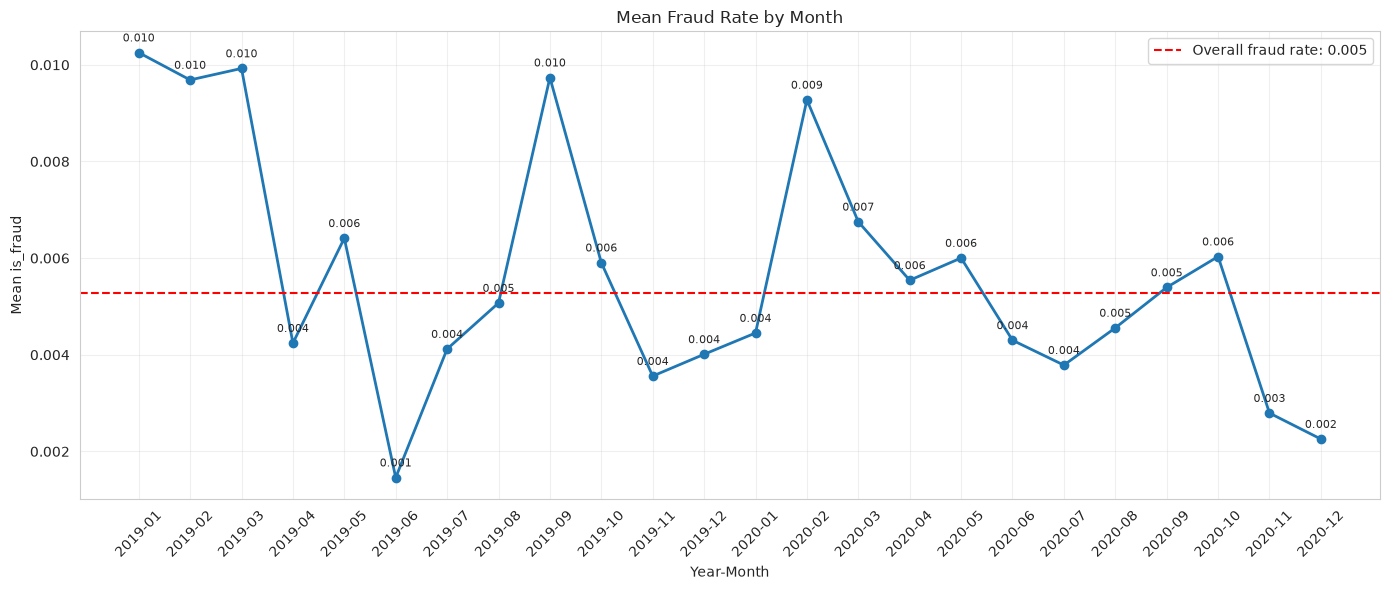

In [21]:
monthly_fraud = raw.groupby("year_month")["is_fraud"].mean().sort_index()

x = monthly_fraud.index.astype(str).tolist()
y = monthly_fraud.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, y, marker="o", linewidth=2)

for i, (month, rate) in enumerate(monthly_fraud.items()):
    ax.annotate(
        f"{rate:.3f}",
        (x[i], float(rate)),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )

ax.set_title("Mean Fraud Rate by Month")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Mean is_fraud")
overall_fraud_rate = raw["is_fraud"].mean()
ax.axhline(
    overall_fraud_rate,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall fraud rate: {overall_fraud_rate:.3f}",
)
ax.legend(loc="upper right")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
df = raw
df["ym"] = pd.to_datetime(df["created_at"], utc=True).dt.strftime("%Y-%m")
conds = [df.ym < "2019-02", df.ym.between("2019-02", "2020-04"), df.ym == "2020-05",
         df.ym.between("2020-06", "2020-08"), df.ym == "2020-09", df.ym >= "2020-10"]
df["split"] = np.select(
    conds,
    ["warmup", "train", "gap1", "valid", "gap2", "test"],
    default="unassigned",
)
print(df.groupby("split")["is_fraud"].agg(["size", "sum", "mean"]))

          size   sum      mean
split                         
gap1     13494    81  0.006003
gap2     12793    69  0.005394
test     51557   171  0.003317
train   203934  1159  0.005683
valid    48135   203  0.004217
warmup   11606   119  0.010253


                  n  fraud      rate        lo        hi  share_volume
card_brand                                                            
Amex          57054    279  0.004890  0.004350  0.005497      0.167060
Master Card  113945    613  0.005380  0.004971  0.005822      0.333642
Visa         170520    910  0.005337  0.005002  0.005694      0.499299
qui-quadrado p = 0.3730677254501365


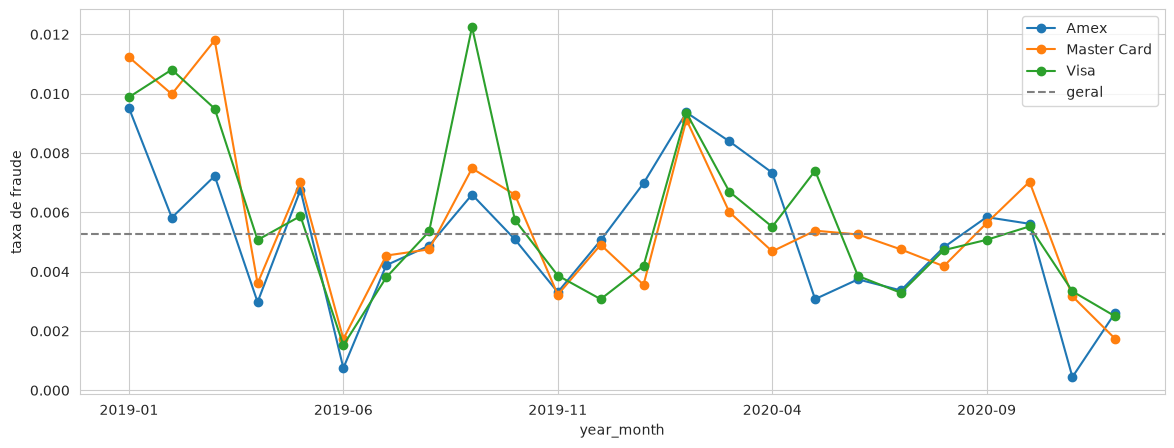

In [35]:


# 1) taxa por bandeira no período todo, com IC
t = df.groupby("card_brand")["is_fraud"].agg(n="size", fraud="sum", rate="mean")
t["lo"], t["hi"] = proportion_confint(t["fraud"], t["n"], method="wilson")
t["share_volume"] = t["n"] / t["n"].sum()
print(t)
print("qui-quadrado p =", chi2_contingency(pd.crosstab(df["card_brand"], df["is_fraud"]))[1])

# 2) evolução mensal, sem empilhar
fb = df.groupby(["year_month", "card_brand"])["is_fraud"].mean().unstack()
ax = fb.plot(marker="o", figsize=(14, 5))
ax.axhline(df["is_fraud"].mean(), color="gray", ls="--", label="geral")
ax.set_ylabel("taxa de fraude"); ax.legend(); plt.show()

In [38]:
def cat_report(d, col, min_n=500):
    t = d.groupby(col)["is_fraud"].agg(n="size", fraud="sum", rate="mean")
    t["lo"], t["hi"] = proportion_confint(t["fraud"], t["n"], method="wilson")
    t["lift"] = t["rate"] / d["is_fraud"].mean()
    t["share"] = t["n"] / t["n"].sum()
    t = t[t["n"] >= min_n].sort_values("rate", ascending=False)   # corta categorias raras
    p = chi2_contingency(pd.crosstab(d[col], d["is_fraud"]))[1]
    return t, p



In [40]:
cat_report(raw, 'vertical')

(                    n  fraud      rate        lo        hi      lift     share
 vertical                                                                      
 shopping_net    26538    386  0.014545  0.013173  0.016057  2.756635  0.077706
 grocery_pos     32927    437  0.013272  0.012091  0.014566  2.515297  0.096413
 misc_net        17008    219  0.012876  0.011289  0.014684  2.440343  0.049801
 shopping_pos    30499    190  0.006230  0.005407  0.007177  1.180669  0.089304
 gas_transport   35307    155  0.004390  0.003752  0.005136  0.832015  0.103382
 travel          10378     33  0.003180  0.002265  0.004462  0.602643  0.030388
 misc_pos        20139     63  0.003128  0.002446  0.004000  0.592874  0.058969
 grocery_net     11426     28  0.002451  0.001696  0.003539  0.464434  0.033456
 entertainment   24329     55  0.002261  0.001737  0.002941  0.428448  0.071238
 personal_care   24542     55  0.002241  0.001722  0.002916  0.424730  0.071861
 kids_pets       29860     56  0.001875 